# 6. Tutorial 6

**Course:** High Switching Frequency Power Converters

## 6.1 Saturation or loss limit

A MnZn power ferrite is described at $100~^\circ\mathrm{C}$ by $P_\mathrm{v} = 80~\mathrm{kW/m^3}$ at $100~\mathrm{kHz}$ and $100~\mathrm{mT}$ (sinusoidal), $\alpha = 1.4$, $\beta = 2.5$ and $B_\mathrm{sat} = 370~\mathrm{mT}$. The allowed loss density is $300~\mathrm{kW/m^3}$.

6.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.integrate) and create the function `get_B_max(f, P_max, P_ref, f_ref, B_ref, alpha, beta, B_sat)` that returns the largest allowed flux density amplitude: the smaller of $B_\mathrm{sat}$ and the loss-limited value.

6.1.2 Print the frequency $f_\mathrm{x}$ at which the limit changes from saturation to core loss, and $\hat{B}$ and $\hat{B}f$ at $100~\mathrm{kHz}$ and $400~\mathrm{kHz}$. Plot $\hat{B}$ and $\hat{B}f$ versus frequency in the range [$10~\mathrm{kHz} \ldots 1~\mathrm{MHz}$] (log axes).


In [1]:
# Subtask 6.1.1 Import necessary modules and create the function
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate


def get_B_max(f, P_max, P_ref, f_ref, B_ref, alpha, beta, B_sat):
    """Largest allowed flux density amplitude (same unit as B_ref): saturation or loss limit."""
    B_loss = B_ref * (P_max / (P_ref * (f / f_ref)**alpha))**(1 / beta)
    return np.minimum(B_sat, B_loss)


f_x = 24.9 kHz
f = 100 kHz: B = 169.7 mT, B*f = 17.0 mT*MHz
f = 400 kHz: B = 78.1 mT, B*f = 31.2 mT*MHz
B*f grows with f^0.44 in the loss-limited range


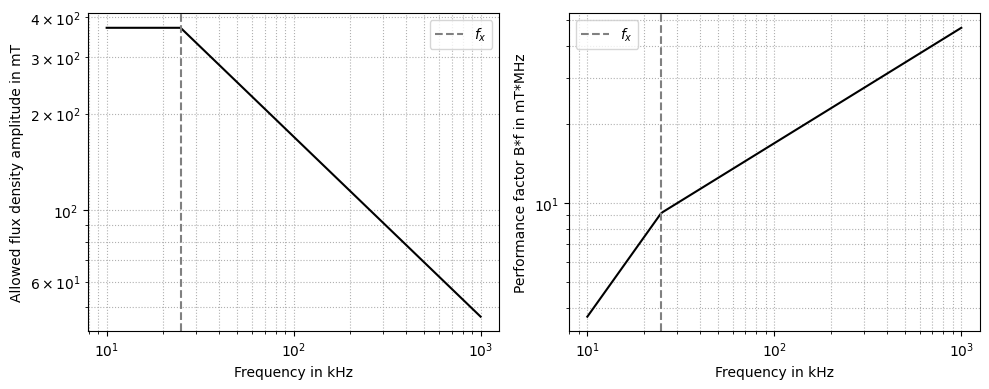

In [2]:
# Subtask 6.1.2 Transition frequency, flux density and performance factor
P_ref, f_ref, B_ref, alpha, beta, B_sat, P_max = 80.0, 100e3, 100.0, 1.4, 2.5, 370.0, 300.0
f_x = f_ref * (P_max / (P_ref * (B_sat / B_ref)**beta))**(1 / alpha)
print(f"f_x = {f_x/1e3:.1f} kHz")
for f in (100e3, 400e3):
    B = get_B_max(f, P_max, P_ref, f_ref, B_ref, alpha, beta, B_sat)
    print(f"f = {f/1e3:.0f} kHz: B = {B:.1f} mT, B*f = {B*f/1e6:.1f} mT*MHz")
print(f"B*f grows with f^{1 - alpha/beta:.2f} in the loss-limited range")

if __name__ == "__main__":
    f = np.logspace(4, 6, 200)
    B = get_B_max(f, P_max, P_ref, f_ref, B_ref, alpha, beta, B_sat)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].loglog(f / 1e3, B, 'k')
    ax[0].axvline(f_x / 1e3, color='gray', ls='--', label='$f_x$')
    ax[0].set_xlabel('Frequency in kHz'); ax[0].set_ylabel('Allowed flux density amplitude in mT')
    ax[1].loglog(f / 1e3, B * f / 1e6, 'k')
    ax[1].axvline(f_x / 1e3, color='gray', ls='--', label='$f_x$')
    ax[1].set_xlabel('Frequency in kHz'); ax[1].set_ylabel('Performance factor B*f in mT*MHz')
    for a in ax:
        a.grid(True, which='both', ls=':'); a.legend()
    plt.tight_layout(); plt.show()


### 6.1.2 Solution

At $B_\mathrm{sat}$ the loss density would be $2107~\mathrm{kW/m^3}$ at $100~\mathrm{kHz}$; it falls to the allowed $300~\mathrm{kW/m^3}$ at $f_\mathrm{x} = 24.9~\mathrm{kHz}$. Above $f_\mathrm{x}$ core loss limits the flux density: $\hat{B} = 170~\mathrm{mT}$ at $100~\mathrm{kHz}$ and $78~\mathrm{mT}$ at $400~\mathrm{kHz}$. The performance factor rises only with $f^{1-\alpha/\beta} = f^{0.44}$, from $17.0$ to $31.2~\mathrm{mT\cdot MHz}$ for four times the frequency.


## 6.2 Performance factor in the HF range

Steinmetz fits of Fair-Rite 67 measured by Hanson et al. (IEEE TPEL, 2016, Table II), $P_\mathrm{v} = k\hat{B}^{\beta}$ with $P_\mathrm{v}$ in $\mathrm{mW/cm^3}$ and $\hat{B}$ in mT:

| $f$ (MHz) | 2 | 5 | 7 | 10 | 13 | 16 | 20 |
|---|---|---|---|---|---|---|---|
| $k$ | 0.10 | 0.69 | 1.11 | 2.09 | 2.91 | 6.06 | 10.95 |
| $\beta$ | 2.44 | 2.20 | 2.18 | 2.08 | 2.18 | 2.04 | 1.99 |

6.2.1 Create the function `get_B_at_Pv(k, beta, P_v)` and compute $\hat{B}$ at $500~\mathrm{mW/cm^3}$ and the performance factors $\hat{B}f$, $\hat{B}f^{3/4}$ and $\hat{B}f^{1/2}$ for all frequencies. Plot the three performance factors normalised to their value at $2~\mathrm{MHz}$.

6.2.2 Compute the loss density at $\hat{B} = 10~\mathrm{mT}$ for all frequencies and the local frequency exponent $\alpha$ between neighbouring frequencies.


 f/MHz   B/mT    B*f   B*f^0.75   B*f^0.5
    2   32.81    65.6      55.2      46.4
    5   19.96    99.8      66.7      44.6
    7   16.49   115.4      71.0      43.6
   10   13.92   139.2      78.3      44.0
   13   10.60   137.8      72.6      38.2
   16    8.70   139.2      69.6      34.8
   20    6.82   136.5      64.5      30.5


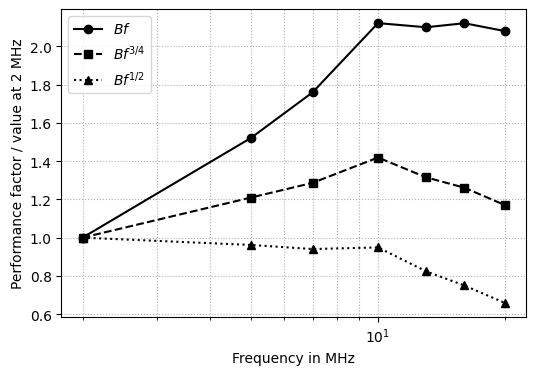

In [3]:
# Subtask 6.2.1 Performance factors of Fair-Rite 67 (Hanson et al. 2016, Table II)
FR67 = {2: (0.10, 2.44), 5: (0.69, 2.20), 7: (1.11, 2.18), 10: (2.09, 2.08),
        13: (2.91, 2.18), 16: (6.06, 2.04), 20: (10.95, 1.99)}   # f in MHz: (k, beta)


def get_B_at_Pv(k, beta, P_v):
    """Flux density amplitude in mT for the loss density P_v in mW/cm^3 (P_v = k*B^beta)."""
    return (P_v / k)**(1 / beta)


f_list = np.array(sorted(FR67))
B500 = np.array([get_B_at_Pv(*FR67[f], 500) for f in f_list])
F1, F34, F12 = B500 * f_list, B500 * f_list**0.75, B500 * f_list**0.5
print(" f/MHz   B/mT    B*f   B*f^0.75   B*f^0.5")
for row in zip(f_list, B500, F1, F34, F12):
    print("{:5d} {:7.2f} {:7.1f} {:9.1f} {:9.1f}".format(*row))

if __name__ == "__main__":
    plt.figure(figsize=(6, 4))
    plt.semilogx(f_list, F1 / F1[0], 'k-o', label='$B f$')
    plt.semilogx(f_list, F34 / F34[0], 'k--s', label='$B f^{3/4}$')
    plt.semilogx(f_list, F12 / F12[0], 'k:^', label='$B f^{1/2}$')
    plt.xlabel('Frequency in MHz'); plt.ylabel('Performance factor / value at 2 MHz')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


In [4]:
# Subtask 6.2.2 Loss density at 10 mT and local frequency exponent
P10 = np.array([FR67[f][0] * 10**FR67[f][1] for f in f_list])
for f, P in zip(f_list, P10):
    print(f"{f:3d} MHz: Pv(10 mT) = {P:7.1f} mW/cm^3")
alpha_local = np.log(P10[1:] / P10[:-1]) / np.log(f_list[1:] / f_list[:-1])
for f1, f2, a in zip(f_list[:-1], f_list[1:], alpha_local):
    print(f"alpha between {f1} and {f2} MHz: {a:.2f}")
print(f"alpha 2-10 MHz: {np.log(P10[3]/P10[0])/np.log(5):.2f}, 10-20 MHz: {np.log(P10[6]/P10[3])/np.log(2):.2f}")


  2 MHz: Pv(10 mT) =    27.5 mW/cm^3
  5 MHz: Pv(10 mT) =   109.4 mW/cm^3
  7 MHz: Pv(10 mT) =   168.0 mW/cm^3
 10 MHz: Pv(10 mT) =   251.3 mW/cm^3
 13 MHz: Pv(10 mT) =   440.4 mW/cm^3
 16 MHz: Pv(10 mT) =   664.5 mW/cm^3
 20 MHz: Pv(10 mT) =  1070.1 mW/cm^3
alpha between 2 and 5 MHz: 1.50
alpha between 5 and 7 MHz: 1.28
alpha between 7 and 10 MHz: 1.13
alpha between 10 and 13 MHz: 2.14
alpha between 13 and 16 MHz: 1.98
alpha between 16 and 20 MHz: 2.14
alpha 2-10 MHz: 1.37, 10-20 MHz: 2.09


### 6.2.2 Solution

$\hat{B}$ at $500~\mathrm{mW/cm^3}$ falls from $32.8~\mathrm{mT}$ at $2~\mathrm{MHz}$ to $6.8~\mathrm{mT}$ at $20~\mathrm{MHz}$. $\hat{B}f$ rises from $66$ to $139~\mathrm{mT\cdot MHz}$ at $10~\mathrm{MHz}$ and then stays flat; $\hat{B}f^{3/4}$ (single-layer windings) peaks at $10~\mathrm{MHz}$ with $1.42$ times the value at $2~\mathrm{MHz}$; $\hat{B}f^{1/2}$ (fixed strand or layer thickness) does not rise at all. At $10~\mathrm{mT}$ the loss grows with $f^{1.37}$ between 2 and $10~\mathrm{MHz}$, but with $f^{2.09}$ between 10 and $20~\mathrm{MHz}$, where $\beta \approx 2.0$: once $\alpha > \beta$ the performance factor falls. The local exponents between neighbouring frequencies scatter (1.1 to 2.1), because each frequency was fitted separately.


## 6.3 Planar transformer for an LLC DC transformer

Full-bridge primary with a square-wave voltage of $\pm 48~\mathrm{V}$ at $1~\mathrm{MHz}$, turns ratio 4:1, core with $A_\mathrm{e} = 40~\mathrm{mm^2}$ and $V_\mathrm{e} = 1.0~\mathrm{cm^3}$. Material at $1~\mathrm{MHz}$ and $100~^\circ\mathrm{C}$: $P_\mathrm{v} = 150~\mathrm{kW/m^3}$ at $50~\mathrm{mT}$ (sinusoidal), $\alpha = 1.5$, $\beta = 2.5$. With $N_\mathrm{p} = 4$ the winding loss is $0.25~\mathrm{W}$; it scales with $N_\mathrm{p}^2$.

6.3.1 Create the functions
- `get_ki(k, alpha, beta)`: coefficient $k_\mathrm{i}$ of the iGSE,
- `get_Pv_igse(t, B, k, alpha, beta)`: iGSE loss density of one period of a piecewise-linear flux waveform given by the corner points `t`, `B` (major loop only, $\Delta B = \max B - \min B$).

Check `get_Pv_igse` with a sampled sinusoid (it must return $k f^{\alpha}\hat{B}^{\beta}$) and print the ratio of the loss of a symmetric triangle to that of a sine with the same $\hat{B}$.

6.3.2 Compute $\hat{B}$, core loss, winding loss and total loss for $N_\mathrm{p}$ in the range [$2 \ldots 12$] (continuous), print the values for $N_\mathrm{p} = 4$ and $8$ and the loss-optimal $N_\mathrm{p}$, and plot the losses.

6.3.3 With extended phase shift the bridge applies $+48~\mathrm{V}$ for $0.4\,T$, $0~\mathrm{V}$ for $0.1\,T$, $-48~\mathrm{V}$ for $0.4\,T$ and $0~\mathrm{V}$ for $0.1\,T$. Compute the iGSE core loss for $N_\mathrm{p} = 4$ and compare it with the square wave.


In [5]:
# Subtask 6.3.1 iGSE functions and check with a sinusoid
def get_ki(k, alpha, beta):
    """Coefficient k_i of the iGSE."""
    I = integrate.quad(lambda th: np.abs(np.cos(th))**alpha, 0, 2 * np.pi)[0]
    return k / ((2 * np.pi)**(alpha - 1) * 2**(beta - alpha) * I)


def get_Pv_igse(t, B, k, alpha, beta):
    """iGSE loss density of one period of a piecewise-linear flux B(t) (corner points, first = last).
    Unit of the result: unit of k * Hz^alpha * (unit of B)^beta."""
    t, B = np.asarray(t, float), np.asarray(B, float)
    T = t[-1] - t[0]
    dB = np.diff(B); dt = np.diff(t)
    DB = B.max() - B.min()
    ki = get_ki(k, alpha, beta)
    return ki * DB**(beta - alpha) * np.sum(np.abs(dB / dt)**alpha * dt) / T


# check with a finely sampled sine: k = 1, f = 1 Hz, B = 1 must give 1
k, alpha, beta = 1.0, 1.5, 2.5
t = np.linspace(0, 1, 20001)
print(f"sine check: {get_Pv_igse(t, np.sin(2*np.pi*t), k, alpha, beta):.4f} (expected 1)")
tri = get_Pv_igse([0, 0.5, 1.0], [-1, 1, -1], k, alpha, beta)
print(f"symmetric triangle / sine with the same amplitude: {tri:.3f}")


sine check: 1.0000 (expected 1)
symmetric triangle / sine with the same amplitude: 0.913


N_p = 4: B = 75.0 mT, P_fe = 0.377 W, P_cu = 0.250 W, total = 0.627 W
N_p = 8: B = 37.5 mT, P_fe = 0.067 W, P_cu = 1.000 W, total = 1.067 W


optimum: N_p = 4.60, B = 65.2 mT, P_fe = 0.266 W, P_cu = 0.331 W, total = 0.597 W, P_fe/P_cu = 0.80 (2/beta = 0.80)


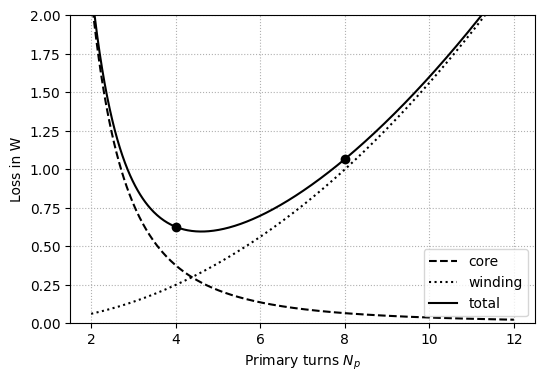

In [6]:
# Subtask 6.3.2 Losses versus number of primary turns
V, f_sw, A_e, V_e = 48.0, 1e6, 40e-6, 1.0e-6
P50, alpha, beta = 150e3, 1.5, 2.5              # W/m^3 at 50 mT, sine
k_T = P50 / (f_sw**alpha * 0.05**beta)          # k for f in Hz, B in T, Pv in W/m^3
P_cu4 = 0.25


def get_losses(N):
    """B in T, core loss, winding loss and total loss in W for N primary turns."""
    B = V / (4 * f_sw * N * A_e)                # square-wave voltage, D = 0.5
    T = 1 / f_sw
    P_fe = get_Pv_igse([0, T / 2, T], [-B, B, -B], k_T, alpha, beta) * V_e
    P_cu = P_cu4 * (N / 4)**2
    return B, P_fe, P_cu, P_fe + P_cu


for N in (4, 8):
    B, P_fe, P_cu, P_tot = get_losses(N)
    print(f"N_p = {N}: B = {B*1e3:.1f} mT, P_fe = {P_fe:.3f} W, P_cu = {P_cu:.3f} W, total = {P_tot:.3f} W")
N_sweep = np.linspace(2, 12, 501)
L = np.array([get_losses(N) for N in N_sweep])
i_opt = np.argmin(L[:, 3])
print(f"optimum: N_p = {N_sweep[i_opt]:.2f}, B = {L[i_opt,0]*1e3:.1f} mT, P_fe = {L[i_opt,1]:.3f} W, "
      f"P_cu = {L[i_opt,2]:.3f} W, total = {L[i_opt,3]:.3f} W, P_fe/P_cu = {L[i_opt,1]/L[i_opt,2]:.2f} (2/beta = {2/beta:.2f})")

if __name__ == "__main__":
    plt.figure(figsize=(6, 4))
    plt.plot(N_sweep, L[:, 1], 'k--', label='core')
    plt.plot(N_sweep, L[:, 2], 'k:', label='winding')
    plt.plot(N_sweep, L[:, 3], 'k', label='total')
    for N in (4, 8):
        plt.plot(N, get_losses(N)[3], 'ko')
    plt.xlabel('Primary turns $N_p$'); plt.ylabel('Loss in W'); plt.ylim(0, 2)
    plt.grid(True, ls=':'); plt.legend(); plt.show()


In [7]:
# Subtask 6.3.3 Three-level bridge voltage (extended phase shift)
T = 1 / f_sw; N = 4
dB = V * 0.4 * T / (N * A_e)                    # flux change during +48 V
t_c = np.array([0, 0.4, 0.5, 0.9, 1.0]) * T
B_c = np.array([-dB / 2, dB / 2, dB / 2, -dB / 2, -dB / 2])
P_trap = get_Pv_igse(t_c, B_c, k_T, alpha, beta) * V_e
P_sq = get_losses(N)[1]
print(f"three-level: B = {dB/2*1e3:.1f} mT, P_fe = {P_trap:.3f} W ({P_trap/P_sq:.2f} of the square wave, {P_sq:.3f} W)")


three-level: B = 60.0 mT, P_fe = 0.242 W (0.64 of the square wave, 0.377 W)


### 6.3.3 Solution

A symmetric triangle has $0.913$ times the loss of a sine with the same amplitude ($\alpha = 1.5$). With $N_\mathrm{p} = 4$: $\hat{B} = 75~\mathrm{mT}$, $P_\mathrm{fe} = 0.377~\mathrm{W}$, $P_\mathrm{cu} = 0.25~\mathrm{W}$, total $0.63~\mathrm{W}$; with $N_\mathrm{p} = 8$: $37.5~\mathrm{mT}$, $0.067~\mathrm{W}$ and $1.0~\mathrm{W}$, total $1.07~\mathrm{W}$. The optimum lies at $N_\mathrm{p} = 4.6$ ($0.60~\mathrm{W}$, $P_\mathrm{fe}/P_\mathrm{cu} = 2/\beta = 0.8$), which a 4:1 ratio with integer turns cannot realise; $N_\mathrm{p} = 4$ costs only 5 % more. With the three-level voltage the flux swing drops to $80~\%$ and the iGSE loss to $0.64$ of the square-wave value ($0.24~\mathrm{W}$). The iGSE does not count the relaxation loss during the zero-voltage intervals, so the real loss will be higher.


## 6.4 Inductor of a ZVS buck converter

TCM buck converter $48~\mathrm{V} \rightarrow 12~\mathrm{V}$, $100~\mathrm{W}$, $2~\mathrm{MHz}$; $L = 225~\mathrm{nH}$ with $N = 3$ turns on a core with $A_\mathrm{e} = 20~\mathrm{mm^2}$, $l_\mathrm{e} = 30~\mathrm{mm}$; Fair-Rite 67 at $2~\mathrm{MHz}$ ($k = 0.10$, $\beta = 2.44$), assume $\alpha = 1.5$.

6.4.1 Compute the current ripple, the minimum and maximum inductor current, $\Delta B$, $\hat{B}$ and $B_\mathrm{dc}$.

6.4.2 Compute the core loss with the sinusoidal data and with the iGSE. Plot the ratio of the iGSE loss to the sinusoidal loss versus the duty cycle in the range [$0.05 \ldots 0.95$] for $\alpha = 1.2$, $1.5$ and $1.8$.



In [8]:
# Subtask 6.4.1 Ripple, flux swing and DC flux
V_in, V_o, f_sw, P_o = 48.0, 12.0, 2e6, 100.0
L_ind, N, A_e, l_e = 225e-9, 3, 20e-6, 30e-3
D = V_o / V_in; T = 1 / f_sw; I_o = P_o / V_o
di = (V_in - V_o) * D * T / L_ind
dB = (V_in - V_o) * D * T / (N * A_e)
B_ac = dB / 2
B_dc = L_ind * I_o / (N * A_e)
print(f"D = {D:.2f}, ripple = {di:.1f} A, i_min = {I_o - di/2:.2f} A, i_max = {I_o + di/2:.2f} A")
print(f"dB = {dB*1e3:.1f} mT, B_ac = {B_ac*1e3:.1f} mT, B_dc = {B_dc*1e3:.1f} mT, B_peak = {(B_ac+B_dc)*1e3:.1f} mT")


D = 0.25, ripple = 20.0 A, i_min = -1.67 A, i_max = 18.33 A
dB = 75.0 mT, B_ac = 37.5 mT, B_dc = 31.2 mT, B_peak = 68.7 mT


sine data: 693 mW/cm^3, iGSE: 705 mW/cm^3, core loss 0.423 W (V_e = 0.60 cm^3)
D = 0.1: ratio 1.361
D = 0.25: ratio 1.018
D = 0.5: ratio 0.913


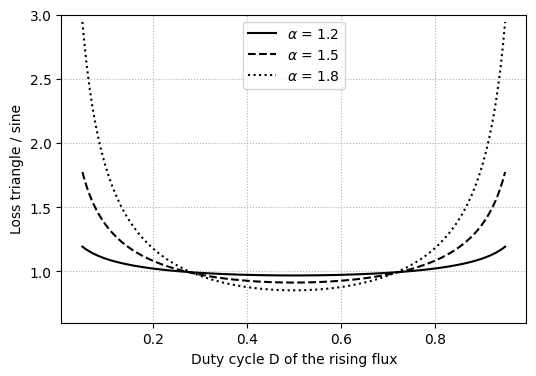

In [9]:
# Subtask 6.4.2 Core loss with sine data and iGSE
k67, beta67, alpha67 = 0.10, 2.44, 1.5           # mW/cm^3 with B in mT, at 2 MHz
V_e = A_e * l_e
P_sine = k67 * (B_ac * 1e3)**beta67              # mW/cm^3
# at the fundamental frequency f_sw the sine loss is k67*B^beta: use k = k67 / f_sw^alpha in get_Pv_igse
k_f = k67 / f_sw**alpha67
P_tri = get_Pv_igse([0, D * T, T], [-B_ac * 1e3, B_ac * 1e3, -B_ac * 1e3], k_f, alpha67, beta67)
print(f"sine data: {P_sine:.0f} mW/cm^3, iGSE: {P_tri:.0f} mW/cm^3, core loss {P_tri * V_e * 1e6 / 1e3:.3f} W (V_e = {V_e*1e6:.2f} cm^3)")


def get_ratio(D, alpha):
    """iGSE loss of a triangle with duty cycle D relative to a sine with the same amplitude."""
    return get_Pv_igse([0, D, 1], [-1, 1, -1], 1.0, alpha, 2.0)


for DD in (0.1, 0.25, 0.5):
    print(f"D = {DD}: ratio {get_ratio(DD, 1.5):.3f}")

if __name__ == "__main__":
    D_sweep = np.linspace(0.05, 0.95, 181)
    plt.figure(figsize=(6, 4))
    for a, ls in ((1.2, '-'), (1.5, '--'), (1.8, ':')):
        plt.plot(D_sweep, [get_ratio(x, a) for x in D_sweep], 'k' + ls, label=fr'$\alpha$ = {a}')
    plt.xlabel('Duty cycle D of the rising flux'); plt.ylabel('Loss triangle / sine')
    plt.ylim(0.6, 3); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 6.4.2 Solution

The ripple is $20~\mathrm{A}$: the current swings from $-1.7$ to $18.3~\mathrm{A}$ and reverses, as ZVS needs. $\Delta B = 75~\mathrm{mT}$, $\hat{B} = 37.5~\mathrm{mT}$, $B_\mathrm{dc} = 31~\mathrm{mT}$, peak $69~\mathrm{mT}$, far below saturation. The sine data give $693~\mathrm{mW/cm^3}$, the iGSE for $D = 0.25$ $705~\mathrm{mW/cm^3}$ ($0.42~\mathrm{W}$ in $0.6~\mathrm{cm^3}$). This is more than the $500~\mathrm{mW/cm^3}$ assumed for the performance factor: more turns or a larger core are needed. For $D = 0.1$ the loss would be 36 % above the sine value.


## 6.5 Permeability and gap

6.5.1 For the inductor of Task 6.4 compute the threshold permeability $\mu_\mathrm{r,th}$, the gap length for $\mu_\mathrm{r} = 40$ and $\mu_\mathrm{r} = 750$, and the share of the magnetic energy stored in the gap.


In [10]:
# Subtask 6.5.1 Threshold permeability and gap
mu0 = 4e-7 * np.pi
mu_th = L_ind * l_e / (mu0 * N**2 * A_e)
print(f"mu_r,th = {mu_th:.1f}")
for mu_r in (40, 750):
    l_g = mu0 * N**2 * A_e / L_ind - l_e / mu_r
    share = l_g / (l_g + l_e / mu_r)
    print(f"mu_r = {mu_r}: gap = {l_g*1e3:.3f} mm, energy share in the gap = {share:.0%}")


mu_r,th = 29.8
mu_r = 40: gap = 0.255 mm, energy share in the gap = 25%
mu_r = 750: gap = 0.965 mm, energy share in the gap = 96%


### 6.5.1 Solution

$\mu_\mathrm{r,th} = 29.8$: with $\mu_\mathrm{r} = 40$ a gap of $0.26~\mathrm{mm}$ stores 25 % of the energy; with $\mu_\mathrm{r} = 750$ a gap of $0.97~\mathrm{mm}$ stores 96 % and its fringing field reaches the winding. A material with $\mu_\mathrm{r} \approx 30$ would need no gap at all.


## 6.6 Core-loss data

The file `coreloss_67.csv` (columns `f_MHz`, `B_mT`, `Pv_mWcm3`) contains synthetic measurements of Fair-Rite 67 between $2$ and $20~\mathrm{MHz}$, generated from the fits of Task 6.2 with 5 % scatter.

6.6.1 Load the data. Fit $k$ and $\beta$ for each frequency (linear least squares of $\ln P_\mathrm{v}$ versus $\ln \hat{B}$) and compare them with the table of Task 6.2.

6.6.2 Fit one Steinmetz equation $P_\mathrm{v} = k f^{\alpha}\hat{B}^{\beta}$ to all data, and as the simplest data-driven model a quadratic polynomial of $\ln f$ and $\ln \hat{B}$ for $\ln P_\mathrm{v}$. Print the RMS and maximum relative errors of both models and plot measured versus predicted loss.

6.6.3 Compute $\hat{B}f$ and $\hat{B}f^{3/4}$ at $500~\mathrm{mW/cm^3}$ from the per-frequency fits and from the global Steinmetz fit, and plot them versus frequency.


In [11]:
# Subtask 6.6.1 Load the data and fit k, beta per frequency
data = np.genfromtxt('coreloss_67.csv', delimiter=',', names=True)
f_d, B_d, P_d = data['f_MHz'], data['B_mT'], data['Pv_mWcm3']
fits = {}
print(" f/MHz   k_fit  beta_fit   k_table beta_table")
for f in np.unique(f_d):
    m = f_d == f
    beta_fit, lnk = np.polyfit(np.log(B_d[m]), np.log(P_d[m]), 1)
    fits[int(f)] = (np.exp(lnk), beta_fit)
    print(f"{int(f):5d} {np.exp(lnk):8.3f} {beta_fit:8.2f} {FR67[int(f)][0]:9.2f} {FR67[int(f)][1]:9.2f}")


 f/MHz   k_fit  beta_fit   k_table beta_table
    2    0.092     2.47      0.10      2.44
    5    0.707     2.19      0.69      2.20
    7    1.092     2.18      1.11      2.18
   10    2.233     2.06      2.09      2.08
   13    2.990     2.17      2.91      2.18
   16    5.913     2.07      6.06      2.04
   20   13.102     1.90     10.95      1.99


global Steinmetz: k = 0.0904, alpha = 1.48, beta = 2.08 (f in MHz, B in mT)
Steinmetz : RMS error 19.4%, max error 37.6%
quadratic : RMS error 9.6%, max error 23.0%
per-frequency fits: RMS error 4.0%, max error 8.6%


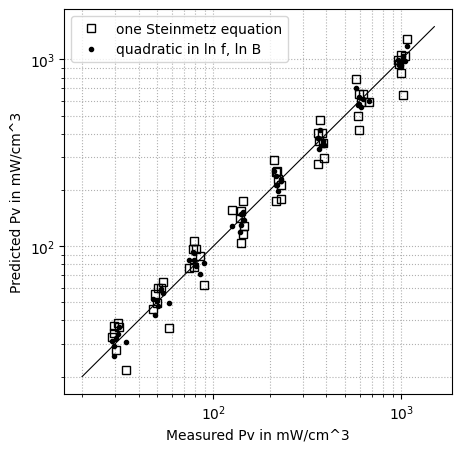

In [12]:
# Subtask 6.6.2 One Steinmetz equation and a quadratic data-driven model
x, y, z = np.log(f_d), np.log(B_d), np.log(P_d)
A_st = np.column_stack([np.ones_like(x), x, y])
c_st = np.linalg.lstsq(A_st, z, rcond=None)[0]
A_q = np.column_stack([np.ones_like(x), x, y, x**2, x * y, y**2])
c_q = np.linalg.lstsq(A_q, z, rcond=None)[0]
k_g, alpha_g, beta_g = np.exp(c_st[0]), c_st[1], c_st[2]
print(f"global Steinmetz: k = {k_g:.4f}, alpha = {alpha_g:.2f}, beta = {beta_g:.2f} (f in MHz, B in mT)")
for name, A, c in (('Steinmetz', A_st, c_st), ('quadratic', A_q, c_q)):
    err = np.exp(A @ c - z) - 1
    print(f"{name:10s}: RMS error {np.sqrt(np.mean(err**2)):.1%}, max error {np.max(np.abs(err)):.1%}")
P_pf = np.array([fits[int(fi)][0] * Bi**fits[int(fi)][1] for fi, Bi in zip(f_d, B_d)])
err = P_pf / P_d - 1
print(f"per-frequency fits: RMS error {np.sqrt(np.mean(err**2)):.1%}, max error {np.max(np.abs(err)):.1%}")

if __name__ == "__main__":
    plt.figure(figsize=(5, 5))
    plt.loglog(P_d, np.exp(A_st @ c_st), 'ks', mfc='none', label='one Steinmetz equation')
    plt.loglog(P_d, np.exp(A_q @ c_q), 'k.', label='quadratic in ln f, ln B')
    plt.loglog([20, 1500], [20, 1500], 'k-', lw=0.8)
    plt.xlabel('Measured Pv in mW/cm^3'); plt.ylabel('Predicted Pv in mW/cm^3')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


  2 MHz: B*f =   65.4 (per-frequency fit)   77.2 (global fit) mT*MHz
  5 MHz: B*f =   99.9 (per-frequency fit)  100.7 (global fit) mT*MHz
  7 MHz: B*f =  115.9 (per-frequency fit)  110.9 (global fit) mT*MHz
 10 MHz: B*f =  139.1 (per-frequency fit)  123.0 (global fit) mT*MHz
 13 MHz: B*f =  137.1 (per-frequency fit)  132.7 (global fit) mT*MHz
 16 MHz: B*f =  137.1 (per-frequency fit)  140.9 (global fit) mT*MHz
 20 MHz: B*f =  136.4 (per-frequency fit)  150.3 (global fit) mT*MHz


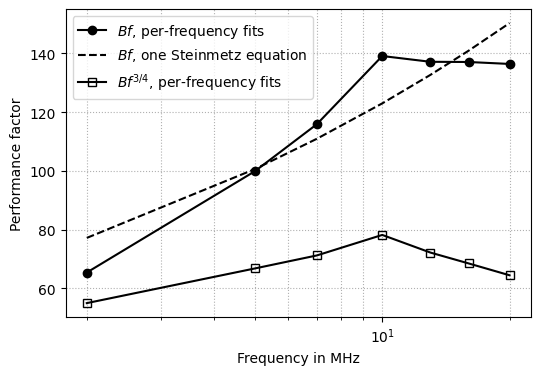

In [13]:
# Subtask 6.6.3 Performance factors from the fits
f_u = np.array(sorted(fits))
B_fit = np.array([get_B_at_Pv(*fits[f], 500) for f in f_u])
B_glob = (500 / (k_g * f_u**alpha_g))**(1 / beta_g)
for f, b1, b2 in zip(f_u, B_fit, B_glob):
    print(f"{f:3d} MHz: B*f = {b1*f:6.1f} (per-frequency fit) {b2*f:6.1f} (global fit) mT*MHz")

if __name__ == "__main__":
    plt.figure(figsize=(6, 4))
    plt.semilogx(f_u, B_fit * f_u, 'k-o', label='$B f$, per-frequency fits')
    plt.semilogx(f_u, B_glob * f_u, 'k--', label='$B f$, one Steinmetz equation')
    plt.semilogx(f_u, B_fit * f_u**0.75, 'k-s', mfc='none', label=r'$B f^{3/4}$, per-frequency fits')
    plt.xlabel('Frequency in MHz'); plt.ylabel('Performance factor')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


### 6.6.3 Solution

The per-frequency fits reproduce the table within the scatter of the data (RMS error 4 %). One Steinmetz equation for 2 to $20~\mathrm{MHz}$ ($\alpha = 1.48$, $\beta = 2.08$) cannot follow the change of $\alpha$ and $\beta$ with frequency: RMS error 19 %, maximum 38 %. The performance factor it predicts is $12~\%$ too low at $10~\mathrm{MHz}$ and keeps rising beyond, instead of levelling off. The quadratic model in $\ln f$ and $\ln \hat{B}$ halves the RMS error. Data-driven models are fits with more freedom; they are only as good as the range of the data behind them.
